In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")


In [4]:
df = pd.read_csv(r"C:\Users\mm com\Downloads\Housing.csv")
print("Shape:", df.shape)
df.head()


Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [13]:
print("Data types:\n")
print(df.dtypes)
print("\nMissing values per column:\n")
print(df.isnull().sum())


Data types:

price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object

Missing values per column:

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [14]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [15]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
for c in cat_cols:
    print(c, "->", df[c].unique())


mainroad -> ['yes' 'no']
guestroom -> ['no' 'yes']
basement -> ['no' 'yes']
hotwaterheating -> ['no' 'yes']
airconditioning -> ['yes' 'no']
prefarea -> ['yes' 'no']
furnishingstatus -> ['furnished' 'semi-furnished' 'unfurnished']


In [16]:
X = df.drop(columns=["price"])
y = df["price"]

numeric_features = ["area", "bedrooms", "bathrooms", "stories", "parking"]
binary_features = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
categorical_features = ["furnishingstatus"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (436, 12)  Test shape: (109, 12)


In [17]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("bin", OneHotEncoder(drop="if_binary"), binary_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

linear_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

poly_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression())
])

print("Pipelines created.")


Pipelines created.


In [18]:
linear_pipeline.fit(X_train, y_train)
poly_pipeline.fit(X_train, y_train)
print("Both models trained.")


Both models trained.


In [19]:
pred_linear = linear_pipeline.predict(X_test)
pred_poly = poly_pipeline.predict(X_test)

mae_linear = mean_absolute_error(y_test, pred_linear)
r2_linear = r2_score(y_test, pred_linear)

mae_poly = mean_absolute_error(y_test, pred_poly)
r2_poly = r2_score(y_test, pred_poly)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (deg=2)"],
    "MAE": [mae_linear, mae_poly],
    "R2 Score": [r2_linear, r2_poly]
})
results


,Model,MAE,R2 Score
0,Linear Regression,9.700434e+05,0.652924
1,Polynomial Regression (deg=2),1.035487e+06,0.623564


In [20]:
print(f"Linear Regression      -> MAE: {mae_linear:,.0f} | R2: {r2_linear:.4f}")
print(f"Polynomial Regression   -> MAE: {mae_poly:,.0f} | R2: {r2_poly:.4f}")

better_model_name = "Linear Regression" if r2_linear >= r2_poly else "Polynomial Regression (deg=2)"
best_pipeline = linear_pipeline if r2_linear >= r2_poly else poly_pipeline
print(f"\nBetter performing model: {better_model_name}")


Linear Regression      -> MAE: 970,043 | R2: 0.6529
Polynomial Regression   -> MAE: 1,035,487 | R2: 0.6236

Better performing model: Linear Regression


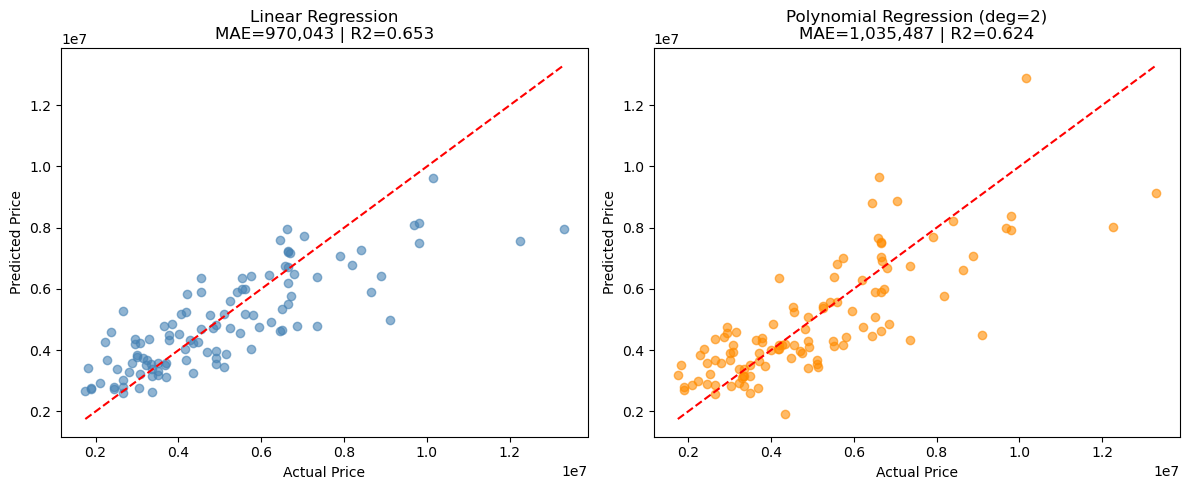

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, pred_linear, alpha=0.6, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_title(f"Linear Regression\nMAE={mae_linear:,.0f} | R2={r2_linear:.3f}")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")

axes[1].scatter(y_test, pred_poly, alpha=0.6, color="darkorange")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_title(f"Polynomial Regression (deg=2)\nMAE={mae_poly:,.0f} | R2={r2_poly:.3f}")
axes[1].set_xlabel("Actual Price")
axes[1].set_ylabel("Predicted Price")

plt.tight_layout()
plt.show()


In [22]:
def predict_price(area, bedrooms, bathrooms, stories, mainroad, guestroom,
                   basement, hotwaterheating, airconditioning, parking,
                   prefarea, furnishingstatus):
    """
    Predict house price from raw input values using the trained pipeline
    (preprocessing + model are applied automatically).
    """
    input_df = pd.DataFrame([{
        "area": area,
        "bedrooms": bedrooms,
        "bathrooms": bathrooms,
        "stories": stories,
        "mainroad": mainroad,
        "guestroom": guestroom,
        "basement": basement,
        "hotwaterheating": hotwaterheating,
        "airconditioning": airconditioning,
        "parking": parking,
        "prefarea": prefarea,
        "furnishingstatus": furnishingstatus
    }])
    predicted_price = best_pipeline.predict(input_df)[0]
    return predicted_price

print("Predictive function ready.")


Predictive function ready.


In [23]:
example_price = predict_price(
    area=6000,
    bedrooms=3,
    bathrooms=2,
    stories=2,
    mainroad="yes",
    guestroom="no",
    basement="yes",
    hotwaterheating="no",
    airconditioning="yes",
    parking=1,
    prefarea="yes",
    furnishingstatus="semi-furnished"
)
print(f"Predicted price for the example house: {example_price:,.0f}")


Predicted price for the example house: 7,187,473
